# 02. Grad-CAM CNN–ViT và attention của ViT

**Câu hỏi 1:** CNN và ViT khác nhau thế nào về phân bố Grad-CAM?  
**Câu hỏi 2:** Attention trong ViT thể hiện điều gì, và có tương đồng với Grad-CAM không?

Thứ tự: **kiểm chứng → pilot ≥100 ảnh → E1 và E3 → phân tích → E4 → E2**.

- `src/attention_gradcam.py`: Grad-CAM, attention, alignment và metrics.
- `src/attention_experiments.py`: dữ liệu, pilot, checkpoint và bảng kết quả.



## 1. Setup và protocol

Giữ **ResNet50 IMAGENET1K_V2** và **ViT-B/16 IMAGENET1K_V1**, cùng official preprocessing của baseline. ResNet resize 232, ViT resize 256, rồi center crop 224. Cùng image ID chưa đồng nghĩa cùng vùng nhìn.

Grad-CAM lấy **ground-truth logit**, kể cả ảnh model dự đoán sai. ViT dùng `encoder.layers[11].ln_1`: đầu vào self-attention cuối, nơi patch tokens còn tác động đến CLS. Không dùng patch tokens ở đầu ra block cuối.

Hai CAM dùng cùng nguyên lý gradient-weighted activation; không giả định chúng đo hoàn toàn cùng một cơ chế nội bộ. Attention là phân tích riêng cho ViT và không phải attribution theo class.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path
project = Path('/content/drive/MyDrive/cnn-vit-interpretability')
assert (project / 'configs/analysis_set.json').is_file()
os.environ['TORCH_HOME'] = '/content/drive/MyDrive/torch-cache'
os.chdir(project)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%pip install -r requirements.txt

In [7]:
from pathlib import Path
import importlib.util
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "configs/analysis_set.json").is_file():
    raise RuntimeError("Mở notebook từ repository root hoặc thư mục notebooks.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.attention_gradcam import agreement, entropy, map_status, sample_grid, crop_intersection
from src.attention_experiments import (
    MODELS, RunStore, load_selection, subsets, pilot, require_pilot,
    run, analyze, plot_examples,
)

HAS_TORCH = all(importlib.util.find_spec(m) is not None for m in ("torch", "torchvision"))
DEVICE = "cpu"
if HAS_TORCH:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print("PyTorch:", torch.__version__, "| Device:", DEVICE)
else:
    print("Thiếu PyTorch/torchvision: chỉ chạy kiểm chứng dữ liệu, metrics và resume. Không tự cài package.")


PyTorch: 2.11.0+cu130 | Device: cuda


In [ ]:
RUN_PILOT = True        # Chạy thử 100 ảnh × 2 model, kiểm chứng dữ liệu, metrics và resume
RUN_CORE = True        # E1: 5.000 ảnh × 2 model; E3: 1.000 ảnh ViT
RUN_E4 = True        # Chạy sau khi đã phân tích E1/E3
RUN_E2 = True         # Ưu tiên cuối, sau E4
CHECK_PINNED_DATA = False  # Kiểm SHA-256 toàn bộ 6,69 GB; không ghi dữ liệu
ANALYSIS_SIZE = 10000  # 5000 or 10000, balanced across 1,000 classes
SEED = 42
RUN_TAG = f"experiment_v3_n{ANALYSIS_SIZE}" 

OUT = ROOT / "results/metrics/attention_gradcam" / RUN_TAG
FIG = ROOT / "results/figures/attention_gradcam" / RUN_TAG
PILOT_OUT = OUT / "pilot"


## 2. Kiểm chứng manifest và baseline

Kiểm đủ 10.000 ảnh, 10 ảnh/class; đối chiếu ID, nhãn, dataset index với dữ liệu local và baseline. Join predictions bằng **image_id**, không theo vị trí dòng.

Tập bổ sung: một ảnh/class từ manifest chung, seed 42. Pilot chọn 100 ảnh cố định và phân bổ qua bốn nhóm: cả hai đúng, chỉ ResNet đúng, chỉ ViT đúng, cả hai sai. Các nhãn giữ nguyên zero-based.

E1 mặc định lấy 10.000 ảnh (10 ảnh/class, seed 42) từ manifest gốc. E3/E4/E2 và pilot được chọn trong tập E1 này.


In [9]:
full_selection = load_selection(ROOT, verify_local=True)
if ANALYSIS_SIZE not in (5000, 10000):
    raise ValueError("ANALYSIS_SIZE must be 5000 or 10000")
selection = (full_selection.groupby("label", group_keys=False)
             .sample(n=ANALYSIS_SIZE // 1000, random_state=SEED)
             .sort_values("image_id").reset_index(drop=True))
subset, pilot_ids = subsets(selection, seed=SEED)
assert len(selection) == ANALYSIS_SIZE and len(subset) == 1000 and len(pilot_ids) == 100
assert selection.groupby("label").size().eq(ANALYSIS_SIZE // 1000).all()
assert set(subset.image_id).issubset(set(selection.image_id))
assert subset.label.nunique() == 1000

OUT.mkdir(parents=True, exist_ok=True)
selection.to_csv(OUT / f"analysis_{ANALYSIS_SIZE}_seed{SEED}.csv", index=False)
subset.to_csv(OUT / "subset_1000_seed42.csv", index=False)
pilot_ids.to_csv(OUT / "pilot_100_seed42.csv", index=False)
display(selection.groupby("group").size().rename("n_analysis").to_frame())
display(pilot_ids.groupby("group").size().rename("n_pilot").to_frame())


,n_analysis
group,
both_correct,7617
both_wrong,1460
resnet_only,465
vit_only,458


,n_pilot
group,
both_correct,25
both_wrong,25
resnet_only,25
vit_only,25


In [10]:
if CHECK_PINNED_DATA:
    import subprocess
    subprocess.run(
        [sys.executable, str(ROOT / "src/create_analysis_manifest.py"), "--check"],
        cwd=ROOT, check=True,
    )


In [ ]:
import matplotlib.pyplot as plt

groups = ["Both correct", "Both wrong", "ResNet only", "ViT only"]
counts = [7617, 1460, 465, 458]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(groups, counts, color="#4C78A8", width=0.6)

# Hiển thị số ảnh trên từng cột
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 80,
        f"{height:,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title("Prediction Correctness Agreement: ResNet50 vs ViT-B/16")
ax.set_ylabel("Number of images")
ax.set_ylim(0, 8500)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 3. Kiểm chứng số học và checkpoint

E1 đưa hai CAM về tọa độ ảnh gốc và lấy **vùng crop giao nhau**, rồi lấy mẫu bilinear tại tâm ô. Grid chính 7×7, sensitivity check 14×14. Không thêm zero vào vùng model chưa thấy.

- Spearman dùng average ranks khi có ties.
- Top-20% chọn đúng ceil(0,2N) ô; ties theo chỉ số row-major.
- Entropy: −Σp log(p)/log(N), p là CAM không âm chia tổng.
- CAM toàn 0, gần hằng, không hữu hạn và gradient không hợp lệ được gắn cờ. Metric không xác định để NaN; entropy theo cặp chỉ dùng hai maps hợp lệ.

Các checks dưới đây không cần PyTorch và không dùng dữ liệu giả làm kết quả nghiên cứu.

In [11]:
import tempfile

a = np.arange(49, dtype=float).reshape(7, 7)
assert np.isclose(agreement(a, a)["spearman"], 1)
assert agreement(a, a)["top20_iou"] == 1
assert agreement(a, a[::-1, ::-1])["top20_iou"] == 0
assert map_status(np.zeros((7, 7))) == "all_zero"
assert map_status(np.ones((7, 7))) == "near_constant"
assert map_status(np.full((7, 7), np.nan)) == "nonfinite"
assert np.isclose(entropy(np.ones((7, 7))), 1)
assert np.isnan(entropy(np.zeros((7, 7))))
assert np.isnan(agreement(a, np.ones((7, 7)))["spearman"])
ties = np.tile(np.arange(7), (7, 1))
assert agreement(ties, ties)["top20_iou"] == 1

# Linear coordinate field: crop alignment must preserve physical locations.
for width, height in ((224, 224), (400, 200), (200, 400)):
    g1 = {"original_size": [width, height], "box": [0., 0., float(width), float(height)]}
    g2 = {"original_size": [width, height],
          "box": [width*.1, height*.1, width*.9, height*.9]}
    region = crop_intersection(g1, g2)
    cams = []
    for geometry in (g1, g2):
        left, top, right, bottom = geometry["box"]
        xx = left + (np.arange(56)+.5)/56*(right-left)
        yy = top + (np.arange(56)+.5)/56*(bottom-top)
        cams.append(xx[None, :] + yy[:, None] + 1)
    # sample_grid normalizes by the source maximum: restore that scale here.
    x = sample_grid(cams[0], g1, 7, region) * cams[0].max()
    y = sample_grid(cams[1], g2, 7, region) * cams[1].max()
    np.testing.assert_allclose(x, y, atol=1e-9)
try:
    sample_grid(a, {"box": [0, 0, 1, 1]}, 7, [-1, 0, 1, 1])
except ValueError:
    pass
else:
    raise AssertionError("Outside-crop sampling must fail")

with tempfile.TemporaryDirectory() as temporary:
    config = {"image_ids": ["a", "b"]}
    store = RunStore(temporary, config)
    store.append([({"image_id": "a"}, {"near_head": a})])
    # An archive without its committed JSON marker must be ignored.
    np.savez(Path(temporary) / "chunk-interrupted.npz", near_head=a)
    resumed = RunStore(temporary, config)
    assert resumed.done == {"a"}
    resumed.append([({"image_id": "b"}, {"near_head": a})])
    assert RunStore(temporary, config).done == {"a", "b"}
    try:
        resumed.append([({"image_id": "a"}, {})])
    except ValueError:
        pass
    else:
        raise AssertionError("Duplicate ID must fail")
    try:
        RunStore(temporary, {"image_ids": ["changed"]})
    except ValueError:
        pass
    else:
        raise AssertionError("Configuration mismatch must fail")
print("PASS: metrics, ties, coordinate alignment, interrupted resume and config checks")


PASS: metrics, ties, coordinate alignment, interrupted resume and config checks


## 4. Pilot ≥100 ảnh — trước lượt chạy chính thức

Thử batch 1/2/4 riêng từng model, float32, eval mode. Sau warm-up, đo compute time, throughput, p95, peak GPU memory; đọc/preprocess và ghi checkpoint đo riêng. Chọn batch lớn nhất vượt qua kiểm chứng.

Kiểm chứng trên toàn pilot:
- Đối chiếu predictions với baseline; sai khác được ghi nhận và cảnh báo, không chặn chạy.
- Logits và CAM theo batch khớp chạy từng ảnh, rtol=1e−4, atol=1e−5.
- Native CAM có kích thước 7×7 / 14×14.
- Attention adapter raw và rollout giữ logits, top-1; attention [B,12,197,197], các hàng tổng bằng 1.

Runtime là ước lượng từ pilot, không cam kết thời gian toàn lượt chạy. E3/E4 timing trong pilot chỉ kiểm tra kỹ thuật; chưa phân tích kết quả mở rộng trước E1/E3.

In [ ]:
DOWNLOAD_MISSING_WEIGHTS = True

if HAS_TORCH:
    from torchvision.models import ResNet50_Weights, ViT_B_16_Weights
    cache_dir = Path(torch.hub.get_dir()) / "checkpoints"
    print("Weights cache:", cache_dir)
    missing_weights = []
    for weights in (ResNet50_Weights.IMAGENET1K_V2, ViT_B_16_Weights.IMAGENET1K_V1):
        path = cache_dir / weights.url.rsplit("/", 1)[-1]
        if not path.is_file() and DOWNLOAD_MISSING_WEIGHTS:
            print("Downloading:", path.name)
            state = weights.get_state_dict(progress=True, check_hash=True)
            del state
        if not path.is_file():
            missing_weights.append(str(path))
    if missing_weights:
        print("Thiếu weights:\n" + "\n".join(missing_weights))
        print("Đặt DOWNLOAD_MISSING_WEIGHTS = True rồi chạy lại cell này để tải một lần. "
              "Nếu đã có weights ở nơi khác, đặt torch.hub.set_dir(...) tới thư mục hub chứa checkpoints rồi chạy lại.")
    else:
        print("Đã có đủ weights cho cả hai model; có thể chạy pilot.")


Weights cache: /content/drive/MyDrive/torch-cache/hub/checkpoints
Đã có đủ weights cho cả hai model; có thể chạy pilot.


In [13]:
pilot_report = None
if RUN_PILOT:
    if not HAS_TORCH:
        raise RuntimeError("Chọn kernel đã có PyTorch/torchvision; notebook không tự cài đặt.")
    pilot_report = pilot(ROOT, pilot_ids, PILOT_OUT, DEVICE)
elif (PILOT_OUT / "pilot.json").exists():
    pilot_report = json.loads((PILOT_OUT / "pilot.json").read_text(encoding="utf-8"))

if pilot_report:
    display(pd.DataFrame(pilot_report["trials"]))
    print("Passed:", pilot_report["passed"])
    if pilot_report["passed"]:
        print("Batch sizes:", pilot_report["batch_sizes"])
        print("Ước lượng E1 (giờ, hai model):", round(pilot_report["estimated_e1_hours"] * ANALYSIS_SIZE / 10000, 2))
        display(pd.DataFrame([pilot_report["attention"]]))
    else:
        print("Pilot chưa đạt kiểm tra kỹ thuật; xem lỗi trước khi chạy chính thức.")
    if pilot_report.get("baseline_mismatches"):
        display(pd.DataFrame(pilot_report["baseline_mismatches"]))
        print("Prediction lệch baseline chỉ là cảnh báo; không chặn khi kiểm tra kỹ thuật đã đạt.")
else:
    print("Chưa có pilot model. Bật RUN_PILOT trong kernel phù hợp.")


Pilot resnet50: 100 images
  batch=1: 0.010s/image; parity=True; baseline=False
  batch=2: 0.005s/image; parity=True; baseline=False
  batch=4: 0.004s/image; parity=True; baseline=False
Pilot vit_b_16: 100 images
  batch=1: 0.016s/image; parity=True; baseline=True
  batch=2: 0.043s/image; parity=True; baseline=True
  batch=4: 0.029s/image; parity=True; baseline=True


/tmp/ipykernel_7076/165027946.py:5: UserWarning: 1 image/model predictions differ from baseline; technical checks passed, so experiments may continue. See baseline_mismatches in pilot.json.
  pilot_report = pilot(ROOT, pilot_ids, PILOT_OUT, DEVICE)


,model,batch_size,status,parity,baseline_match,seconds_per_image,images_per_second,p95_seconds_per_image,read_seconds,reference_write_seconds,peak_gpu_bytes,estimated_e1_hours
0,resnet50,1,ok,True,False,0.010012,99.879551,0.013610,30.227748,0.114621,210522624,0.870655
1,resnet50,2,ok,True,False,0.005302,188.622033,0.005530,30.227748,0.000000,296451072,0.854386
2,resnet50,4,ok,True,False,0.004380,228.331812,0.004595,30.227748,0.000000,471961088,0.851825
3,vit_b_16,1,ok,True,True,0.015533,64.378499,0.025938,28.606537,0.082703,448152064,0.840071
4,vit_b_16,2,ok,True,True,0.043473,23.002671,0.044351,28.606537,0.000000,541256192,0.915385
5,vit_b_16,4,ok,True,True,0.028599,34.966306,0.029079,28.606537,0.000000,683147776,0.874068


Passed: True
Batch sizes: {'resnet50': 4, 'vit_b_16': 4}
Ước lượng E1 (giờ, hai model): 1.73


,raw_parity,rollout_parity,top1_match,row_sum_error,e3_seconds,e4_seconds,shapes
0,True,True,True,4.768372e-07,1.129965,1.233981,"{'block_3': [4, 12, 197, 197], 'block_6': [4, ..."


,image_id,model,label,prediction,baseline_prediction,top1_margin,baseline_logit_gap
0,ILSVRC2012_val_00035791_n02749479.JPEG,resnet50,413,385,830,0.008813,0.008813


Prediction lệch baseline chỉ là cảnh báo; không chặn khi kiểm tra kỹ thuật đã đạt.


## 5. E1 — CNN và ViT khác nhau thế nào về Grad-CAM?

**Dữ liệu:** ANALYSIS_SIZE IDs (mặc định 10.000, 10 ảnh/class) từ manifest chung.  
**Phương pháp:** ResNet layer4[-1], ViT encoder.layers[11].ln_1, cùng ground-truth class.  
**Đầu ra:** Spearman, Top-20% IoU và entropy trên vùng giao crop; grid 7/14. Bảng toàn tập và bốn nhóm đúng/sai.

Tỷ lệ CAM suy biến và lỗi extraction báo riêng, kèm số mẫu hợp lệ. coverage.csv lưu baseline_match theo ảnh; coverage_summary.csv báo số prediction được đối chiếu và tỷ lệ lệch baseline. Các nhóm đúng/sai dùng predictions baseline để giữ cùng cohort; prediction thực tế của lượt chạy được lưu riêng trong checkpoint. Cell full run dùng batch đã qua pilot; checkpoint có kiểm tra code, weights, data, device và cấu hình.

In [14]:
if RUN_CORE:
    batch_sizes = require_pilot(ROOT, pilot_ids, pilot_report or {}, DEVICE)
    for name in MODELS:
        print(f"E1: run/resume {name}, {len(selection)} images", flush=True)
        run(ROOT, selection, name, "E1", OUT, batch_sizes[name], DEVICE)

def available(experiment, name):
    directory = OUT / experiment / name
    if not (directory / "config.json").is_file():
        print(f"{experiment}/{name}: checkpoint missing ({directory})")
        return False
    store = RunStore(directory)
    expected = set((selection if experiment == "E1" else subset).image_id)
    complete = store.done == expected and set(store.config["image_ids"]) == expected
    print(f"{experiment}/{name}: {len(store.done & expected)}/{len(expected)} images processed")
    return complete

e1_results = None
if all(available("E1", name) for name in MODELS):
    resnet_store = RunStore(OUT / "E1/resnet50")
    vit_store = RunStore(OUT / "E1/vit_b_16")
    e1_results = analyze(resnet_store, OUT / "tables/E1", vit_store)
    display(e1_results["summary"])
    display(e1_results["coverage_summary"])
else:
    print("E1 chưa chạy đủ hai model. Không báo kết quả một phần thành kết quả toàn bộ tập đã chọn.")


E1: run/resume resnet50, 10000 images
E1: run/resume vit_b_16, 10000 images
E1/resnet50: 10000/10000 images processed
E1/vit_b_16: 10000/10000 images processed


,grid,model,comparison,group,metric,n_total,n_valid,mean,median
0,7,resnet50,resnet_vs_vit,all,entropy_resnet,10000,10000,0.854282,0.863074
1,7,resnet50,resnet_vs_vit,all,entropy_vit,10000,10000,0.832244,0.865511
2,7,resnet50,resnet_vs_vit,all,entropy_delta_vit_minus_resnet,10000,10000,-0.022038,-0.013804
3,7,resnet50,resnet_vs_vit,all,spearman,10000,10000,-0.014066,-0.043664
4,7,resnet50,resnet_vs_vit,all,top20_iou,10000,10000,0.155077,0.111111
5,14,resnet50,resnet_vs_vit,all,entropy_resnet,10000,10000,0.892542,0.898410
6,14,resnet50,resnet_vs_vit,all,entropy_vit,10000,10000,0.779673,0.800970
7,14,resnet50,resnet_vs_vit,all,entropy_delta_vit_minus_resnet,10000,10000,-0.112869,-0.107093
8,14,resnet50,resnet_vs_vit,all,spearman,10000,10000,-0.008935,-0.030595
9,14,resnet50,resnet_vs_vit,all,top20_iou,10000,10000,0.141438,0.111111


,group,model,stage,n_images,degenerate_rate,failure_rate,n_predictions,baseline_mismatch_rate
0,all,resnet50,near_head,10000,0.0,0.0,10000,0.000800
1,all,vit_b_16,near_head,10000,0.0,0.0,10000,0.000100
2,both_correct,resnet50,near_head,7617,0.0,0.0,7617,0.000000
3,both_correct,vit_b_16,near_head,7617,0.0,0.0,7617,0.000000
4,resnet_only,resnet50,near_head,465,0.0,0.0,465,0.002151
5,resnet_only,vit_b_16,near_head,465,0.0,0.0,465,0.002151
6,vit_only,resnet50,near_head,458,0.0,0.0,458,0.008734
7,vit_only,vit_b_16,near_head,458,0.0,0.0,458,0.000000
8,both_wrong,resnet50,near_head,1460,0.0,0.0,1460,0.002055
9,both_wrong,vit_b_16,near_head,1460,0.0,0.0,1460,0.000000


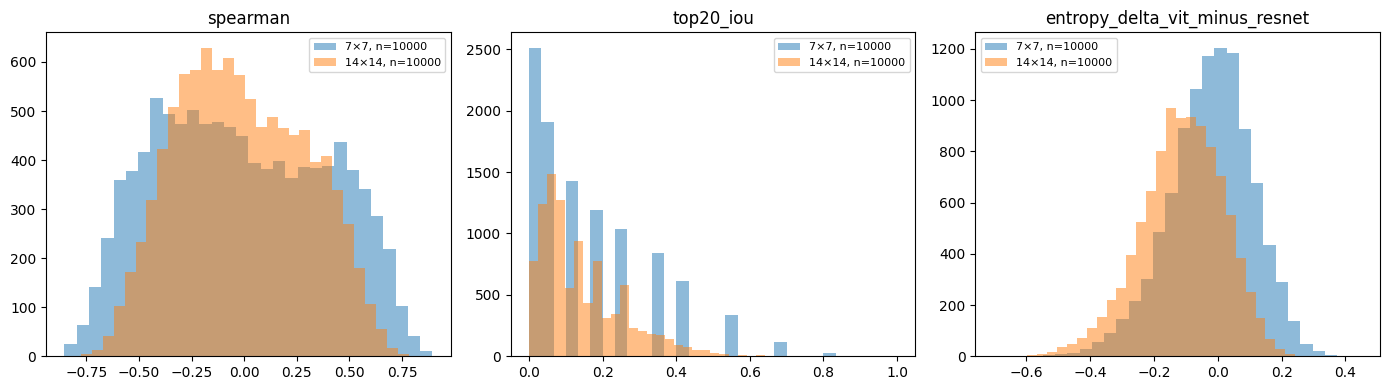

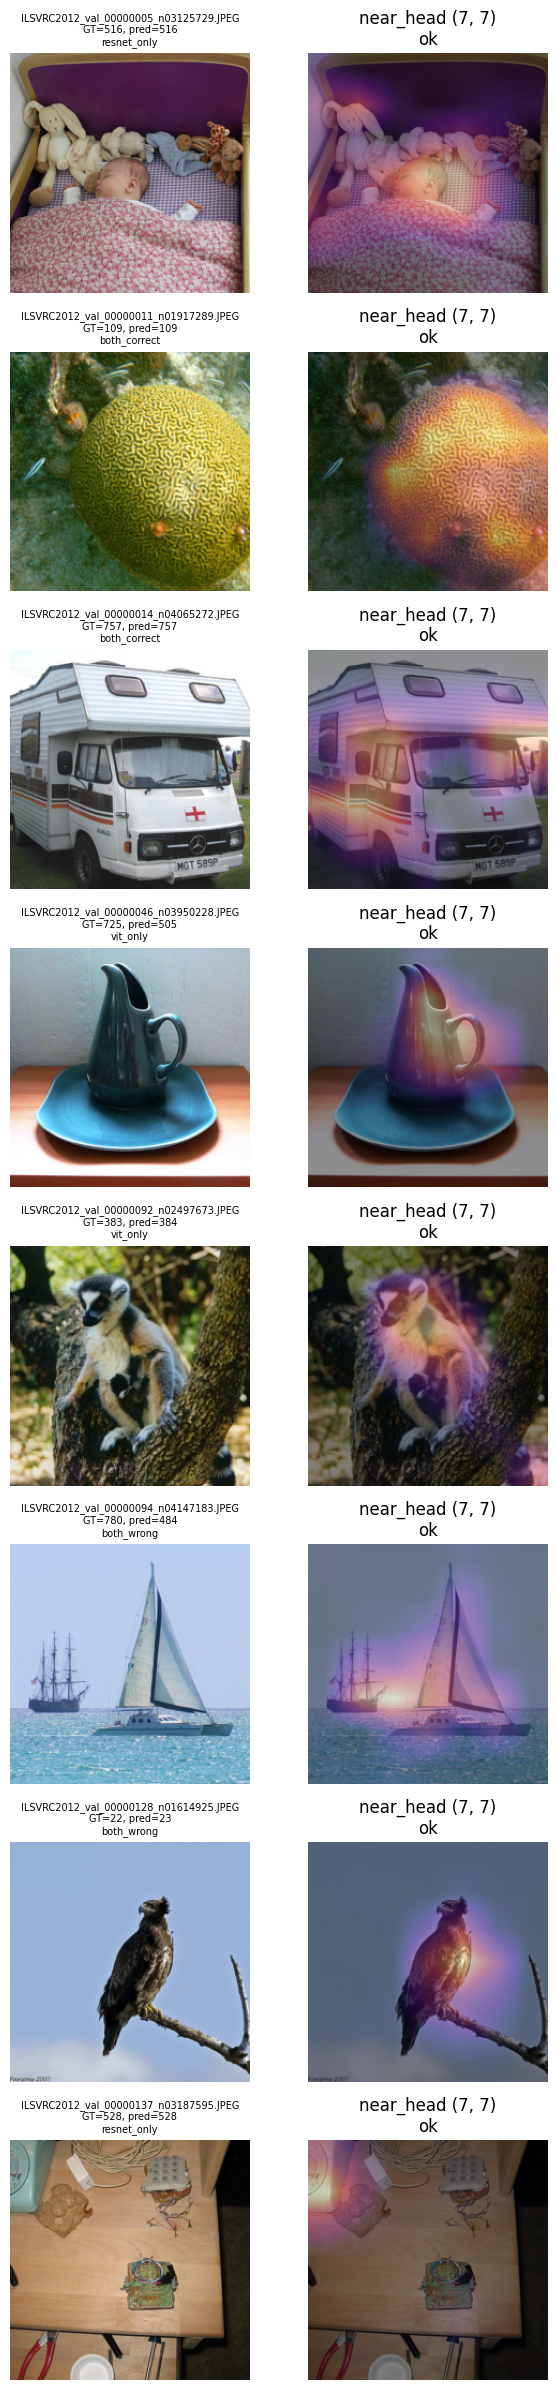

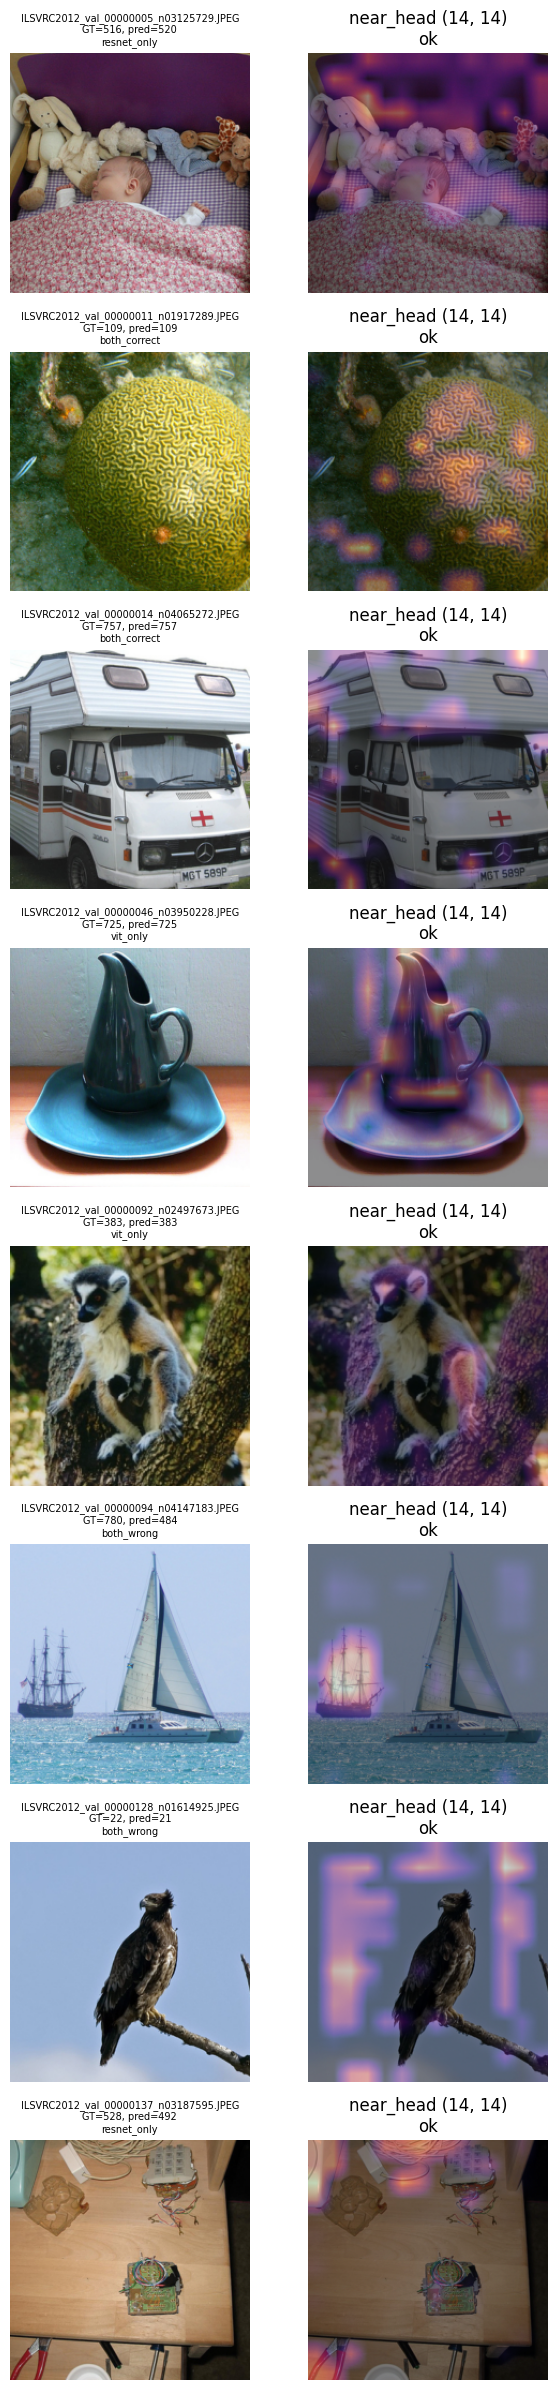

In [15]:
if e1_results is not None:
    frame = e1_results["per_image"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, metric in zip(axes, ["spearman", "top20_iou", "entropy_delta_vit_minus_resnet"]):
        for grid in (7, 14):
            values = frame.loc[frame.grid.eq(grid), metric].dropna()
            ax.hist(values, bins=30, alpha=.5, label=f"{grid}×{grid}, n={len(values)}")
        ax.set_title(metric)
        ax.legend(fontsize=8)
    fig.tight_layout()
    FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG / "E1_distributions.png", dpi=160)
    for name, store in (("resnet50", resnet_store), ("vit_b_16", vit_store)):
        plot_examples(ROOT, store, selection, FIG / f"E1_{name}_examples.png")


In [20]:
import pandas as pd

if e1_results is None:
    raise RuntimeError("E1 results chưa được load.")

summary = e1_results["summary"].copy()

# Chỉ lấy kết quả của toàn bộ tập E1
overall = summary[summary["group"] == "all"]

metrics = {
    "spearman": "Mean Spearman",
    "top20_iou": "Mean Top-20% IoU",
    "entropy_resnet": "ResNet entropy",
    "entropy_vit": "ViT entropy",
    "entropy_delta_vit_minus_resnet": "Entropy: ViT - ResNet",
}

# Lấy mean của từng metric trên từng grid
comparison = (
    overall[overall["metric"].isin(metrics)]
    .pivot(index="metric", columns="grid", values="mean")
    .reindex(metrics.keys())
    .rename(index=metrics, columns={7: "7×7", 14: "14×14"})
)

print("E1 — Grad-CAM Comparison (All Images)")
print("=" * 55)

display(comparison.style.format("{:.4f}"))


E1 — Grad-CAM Comparison (All Images)


grid,7×7,14×14
metric,,
Mean Spearman,-0.0141,-0.0089
Mean Top-20% IoU,0.1551,0.1414
ResNet entropy,0.8543,0.8925
ViT entropy,0.8322,0.7797
Entropy: ViT - ResNet,-0.0220,-0.1129


## 6. E3 — Attention của ViT qua blocks

Lấy CLS-to-patch attention, trung bình 12 heads, tại blocks 3/6/9/12. Lưới gốc 14×14. Tập 1.000 ảnh chung giúp so sánh nhất quán với E4/E2.

Grid minh họa chọn IDs cố định theo nhóm prediction; không chọn theo heatmap đẹp. Attention không phụ thuộc ground-truth target như Grad-CAM. Entropy chỉ mô tả phân bố attention; không chứng minh attention định vị đúng object.

E3: run/resume vit_b_16, 1000 images
E3/vit_b_16: 1000/1000 images processed


,grid,model,stage,group,metric,n_total,n_valid,mean,median
0,7,vit_b_16,block_12,all,entropy,1000,1000,0.798009,0.803139
1,7,vit_b_16,block_12,all,spearman,1000,0,NaN,NaN
2,7,vit_b_16,block_12,all,top20_iou,1000,0,NaN,NaN
3,7,vit_b_16,block_3,all,entropy,1000,1000,0.990888,0.994156
4,7,vit_b_16,block_3,all,spearman,1000,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
115,14,vit_b_16,block_6,both_wrong,spearman,139,0,NaN,NaN
116,14,vit_b_16,block_6,both_wrong,top20_iou,139,0,NaN,NaN
117,14,vit_b_16,block_9,both_wrong,entropy,139,139,0.897632,0.905476
118,14,vit_b_16,block_9,both_wrong,spearman,139,0,NaN,NaN


,group,model,stage,n_images,degenerate_rate,failure_rate,n_predictions,baseline_mismatch_rate
0,all,vit_b_16,block_12,1000,0.0,0.0,1000,0.001000
1,all,vit_b_16,block_3,1000,0.0,0.0,1000,0.001000
2,all,vit_b_16,block_6,1000,0.0,0.0,1000,0.001000
3,all,vit_b_16,block_9,1000,0.0,0.0,1000,0.001000
4,both_correct,vit_b_16,block_12,754,0.0,0.0,754,0.000000
5,both_correct,vit_b_16,block_3,754,0.0,0.0,754,0.000000
6,both_correct,vit_b_16,block_6,754,0.0,0.0,754,0.000000
7,both_correct,vit_b_16,block_9,754,0.0,0.0,754,0.000000
8,resnet_only,vit_b_16,block_12,56,0.0,0.0,56,0.017857
9,resnet_only,vit_b_16,block_3,56,0.0,0.0,56,0.017857


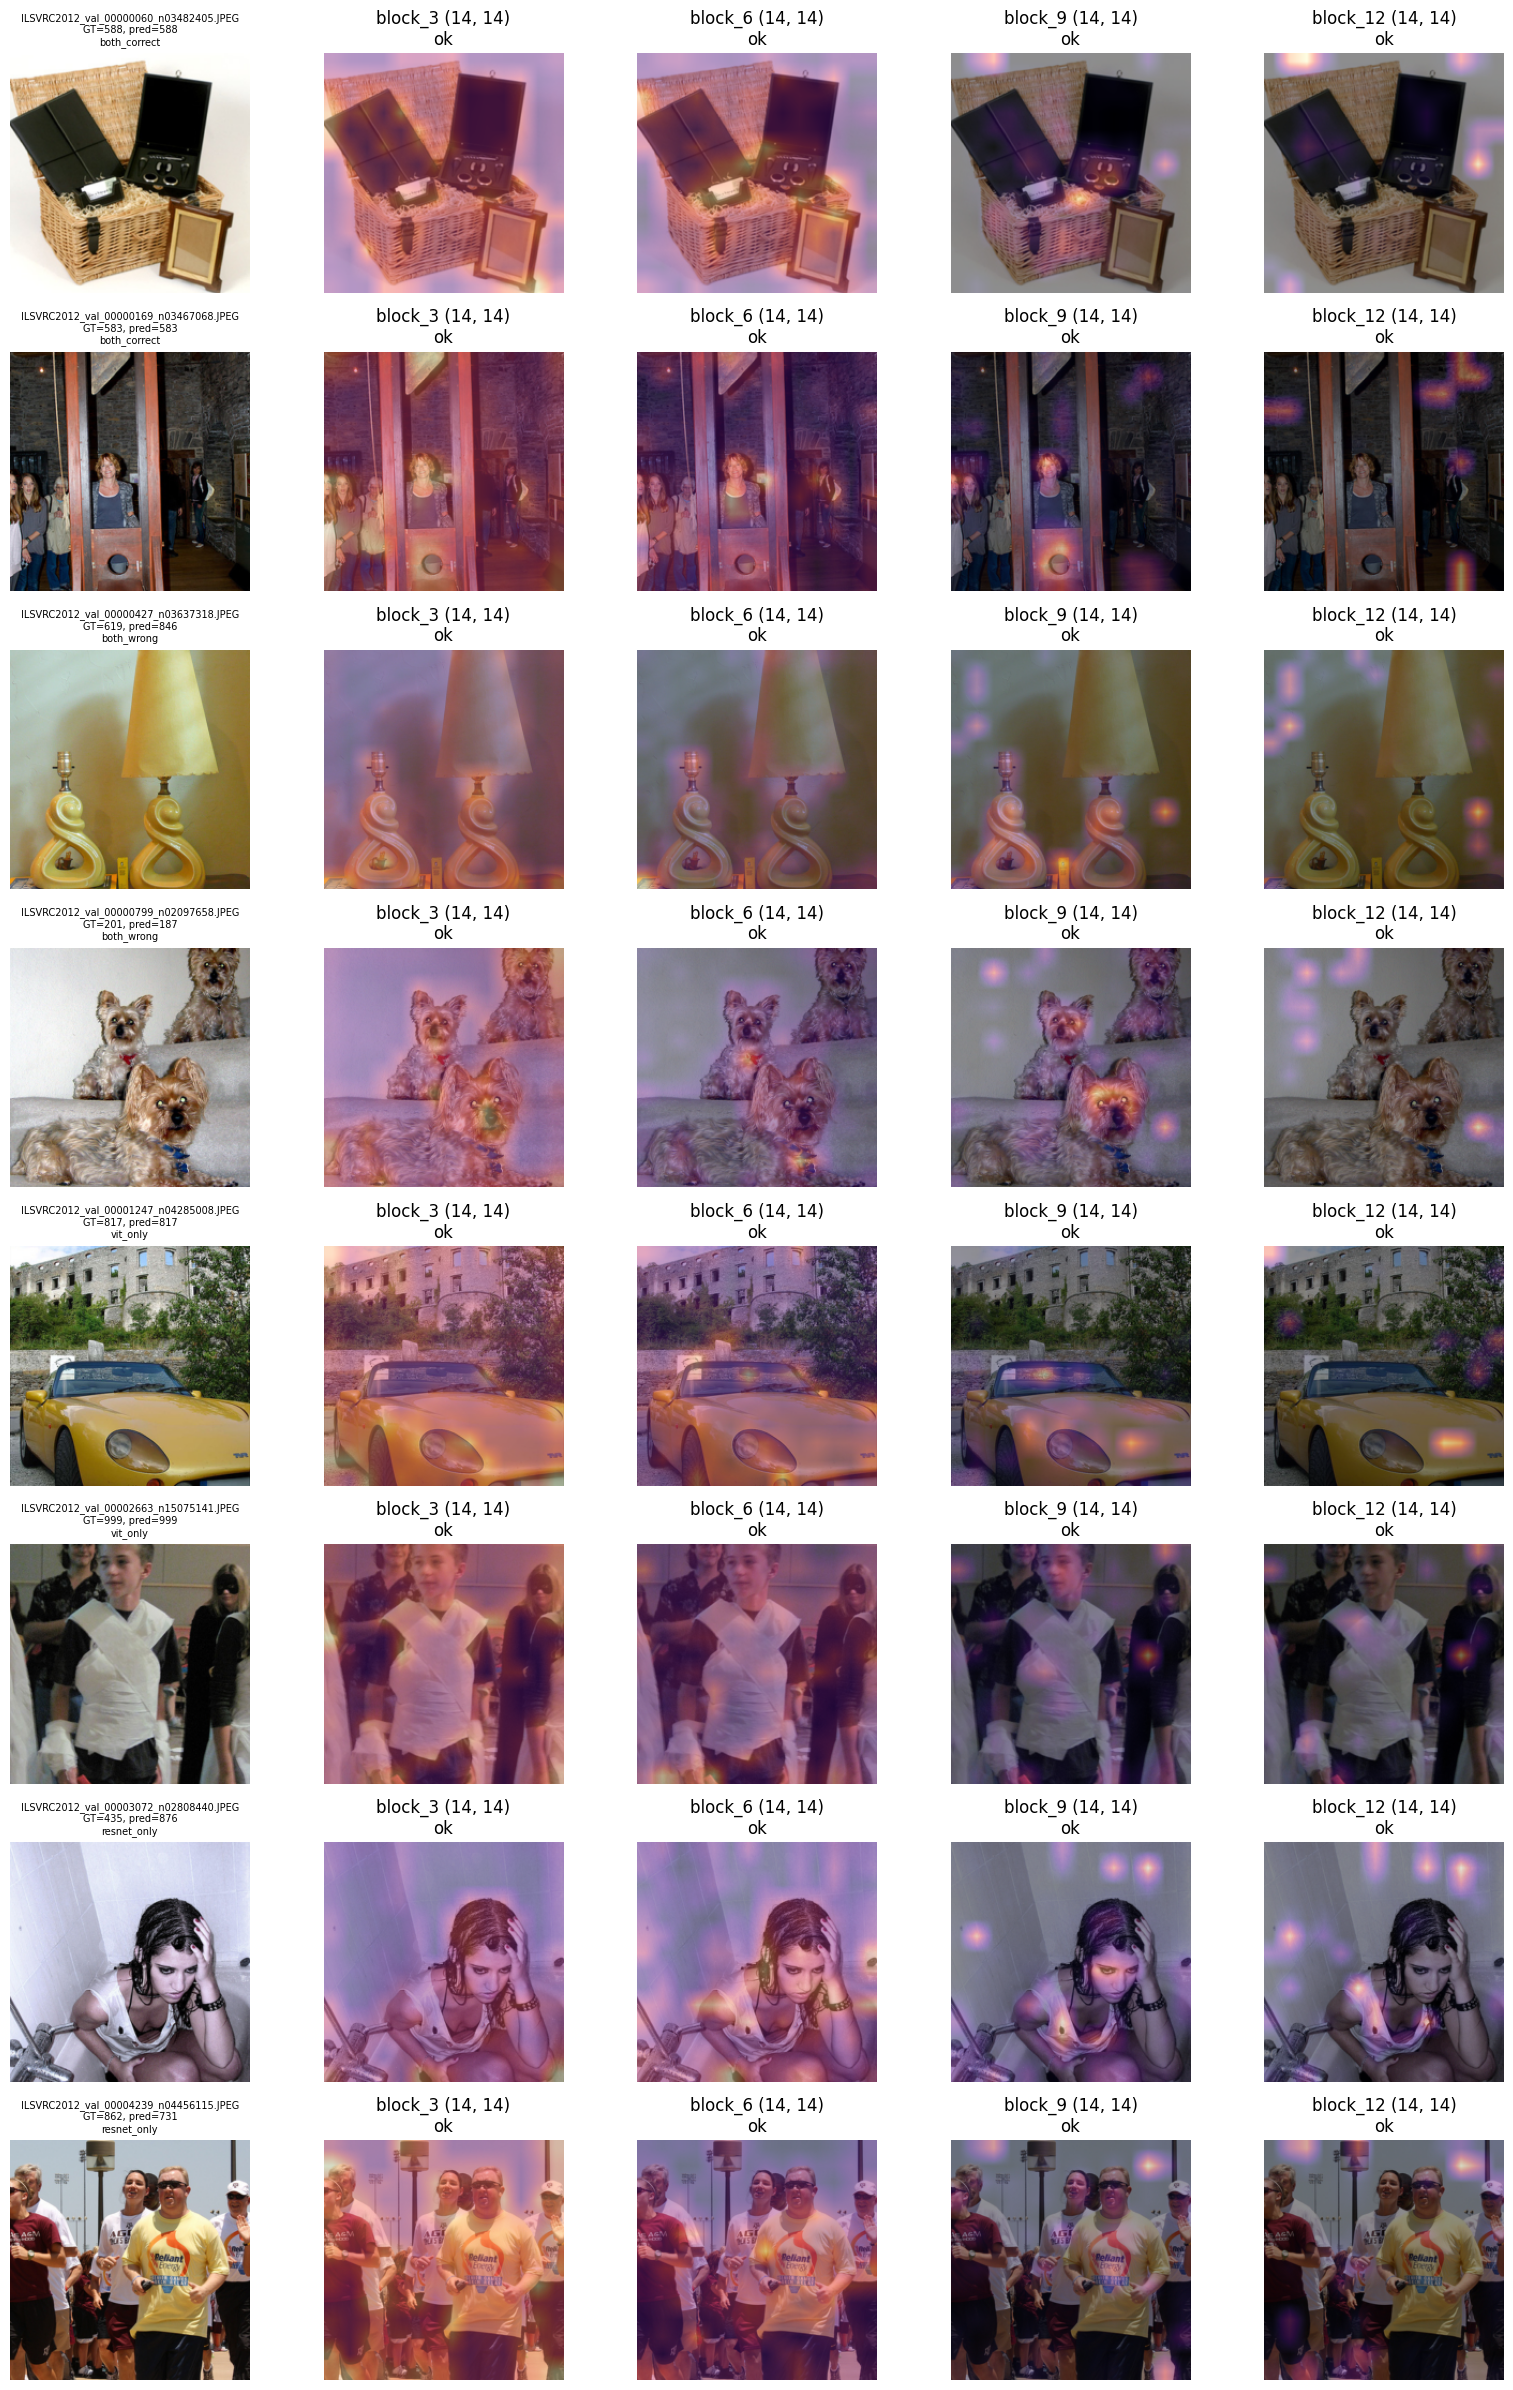

In [16]:
if RUN_CORE:
    batch_sizes = require_pilot(ROOT, pilot_ids, pilot_report or {}, DEVICE)
    print(f"E3: run/resume vit_b_16, {len(subset)} images", flush=True)
    run(ROOT, subset, "vit_b_16", "E3", OUT, batch_sizes["vit_b_16"], DEVICE)

e3_results = None
if available("E3", "vit_b_16"):
    attention_store = RunStore(OUT / "E3/vit_b_16")
    e3_results = analyze(attention_store, OUT / "tables/E3")
    display(e3_results["summary"])
    display(e3_results["coverage_summary"])
    plot_examples(ROOT, attention_store, subset, FIG / "E3_attention_blocks.png")
else:
    print("E3 chưa có kết quả.")


E3 — Mean Attention Entropy (14x14)


stage,block_3,block_6,block_9,block_12
group,,,,
all,0.9894,0.9741,0.8964,0.7222
both_correct,0.9898,0.9746,0.8954,0.7078
resnet_only,0.9866,0.9728,0.8966,0.7624
vit_only,0.9896,0.9740,0.9080,0.7822
both_wrong,0.9880,0.9721,0.8976,0.7622


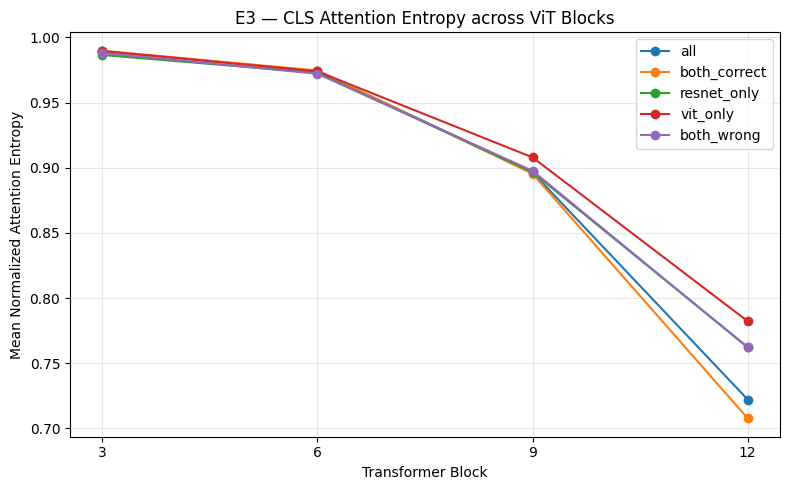

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

df = e3_results["summary"].copy()

# E3: chỉ lấy entropy ở lưới gốc 14x14
df = df[
    (df["metric"] == "entropy") &
    (df["grid"] == 14)
].copy()

block_order = ["block_3", "block_6", "block_9", "block_12"]
group_order = [
    "all", "both_correct", "resnet_only",
    "vit_only", "both_wrong"
]

# Bảng so sánh Mean Entropy
table = df.pivot(
    index="group",
    columns="stage",
    values="mean"
).reindex(index=group_order, columns=block_order)

print("E3 — Mean Attention Entropy (14x14)")
display(table.round(4))

# Biểu đồ entropy theo độ sâu
plt.figure(figsize=(8, 5))

for group in group_order:
    plt.plot(
        [3, 6, 9, 12],
        table.loc[group].values,
        marker="o",
        label=group
    )

plt.xlabel("Transformer Block")
plt.ylabel("Mean Normalized Attention Entropy")
plt.title("E3 — CLS Attention Entropy across ViT Blocks")
plt.xticks([3, 6, 9, 12])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()